# Online Retail Transaction Analysis and Clustering
**Case study notebook — explanatory version**

> Before submission: enter your own title-page details, run every cell, inspect the outputs, and rewrite the interpretation in your own words. Follow your faculty's rules for acknowledging assistance. This notebook is a worked starting point, not a substitute for understanding the methods.

## 1. Problem statement
The dataset contains shopping baskets represented as product names in rows. The goal is to understand transaction characteristics, find popular products, convert baskets to numerical features, visualize them with PCA, compare K-means, hierarchical clustering, DBSCAN and spectral clustering, and discuss business implications.

## 2. Methodology
1. Load the raw CSV **without a header**, because the first line contains transaction items rather than column labels.
2. Normalize product names and remove empty cells.
3. Calculate transaction sizes and product frequencies.
4. Convert each transaction to a binary basket vector (1 = product present, 0 = absent).
5. Use PCA to visualize high-dimensional baskets and produce a compact representation.
6. For practical runtime, compare clustering algorithms on the same reproducible random sample of transactions, using standardized PCA scores.
7. Evaluate with silhouette coefficient (higher is better) and Davies–Bouldin index (lower is better), where metrics are defined. DBSCAN noise points are excluded from its metric calculation.

## 3. Setup

In [13]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

RANDOM_STATE = 42
CSV_PATH = "Online retail_new.csv"  # Keep the CSV in the same folder as this notebook.


## 4. Load and clean the transaction data

Each row is a basket, and each non-empty cell is a product in that basket. Blank cells mean no additional product in that position. We load with `header=None` so the first basket is not accidentally discarded as column headings.

In [14]:
raw = pd.read_csv(CSV_PATH, header=None, dtype=str, encoding_errors="replace")
print("Raw shape:", raw.shape)

# Normalize names and treat blank strings as missing values.
raw = raw.apply(lambda col: col.str.strip().str.lower())
raw = raw.replace("", np.nan)

# Keep transactions as lists of distinct products.
transactions = []
for _, row in raw.iterrows():
    items = [str(x).strip() for x in row.dropna().tolist() if str(x).strip()]
    # Duplicate products in a basket do not increase the binary basket count.
    transactions.append(sorted(set(items)))

transactions = [basket for basket in transactions if basket]
all_items = sorted({item for basket in transactions for item in basket})

print("Number of usable transactions:", len(transactions))
print("Number of unique products:", len(all_items))
print("First cleaned transaction:", transactions[0])
print("Empty transactions removed:", len(raw) - len(transactions))

Raw shape: (7501, 20)
Number of usable transactions: 7501
Number of unique products: 119
First cleaned transaction: ['almonds', 'antioxydant juice', 'avocado', 'cottage cheese', 'energy drink', 'frozen smoothie', 'green grapes', 'green tea', 'honey', 'low fat yogurt', 'mineral water', 'olive oil', 'salad', 'salmon', 'shrimp', 'spinach', 'tomato juice', 'vegetables mix', 'whole weat flour', 'yams']
Empty transactions removed: 0


**Purpose and observation:** This step standardizes capitalization and whitespace so that the same product is not counted under multiple spellings. Empty cells are expected in this dataset because baskets contain different numbers of products. The number of transactions and unique products printed above describe the cleaned dataset.

## 5. Descriptive statistics and product frequency

Transaction size is the number of distinct products in a basket. Product frequency is the number of transactions containing each product; it is not the total quantity sold.

In [15]:
transaction_sizes = pd.Series([len(basket) for basket in transactions], name="transaction_size")
size_summary = transaction_sizes.describe().to_frame().round(2)
print("Transaction-size descriptive statistics:")
display(size_summary)

product_counts = pd.Series(
    {item: sum(item in basket for basket in transactions) for item in all_items},
    name="transaction_count"
).sort_values(ascending=False)

print("\nTop 15 products by number of baskets containing them:")
display(product_counts.head(15).to_frame())

print("Median basket size:", transaction_sizes.median())
print("Most common basket size:", int(transaction_sizes.mode().iloc[0]))

Transaction-size descriptive statistics:


,transaction_size
count,7501.00
mean,3.91
std,2.90
min,1.00
25%,2.00
50%,3.00
75%,5.00
max,20.00



Top 15 products by number of baskets containing them:


,transaction_count
mineral water,1788
eggs,1348
spaghetti,1306
french fries,1282
chocolate,1229
green tea,991
milk,972
ground beef,737
frozen vegetables,715
pancakes,713


Median basket size: 3.0
Most common basket size: 1


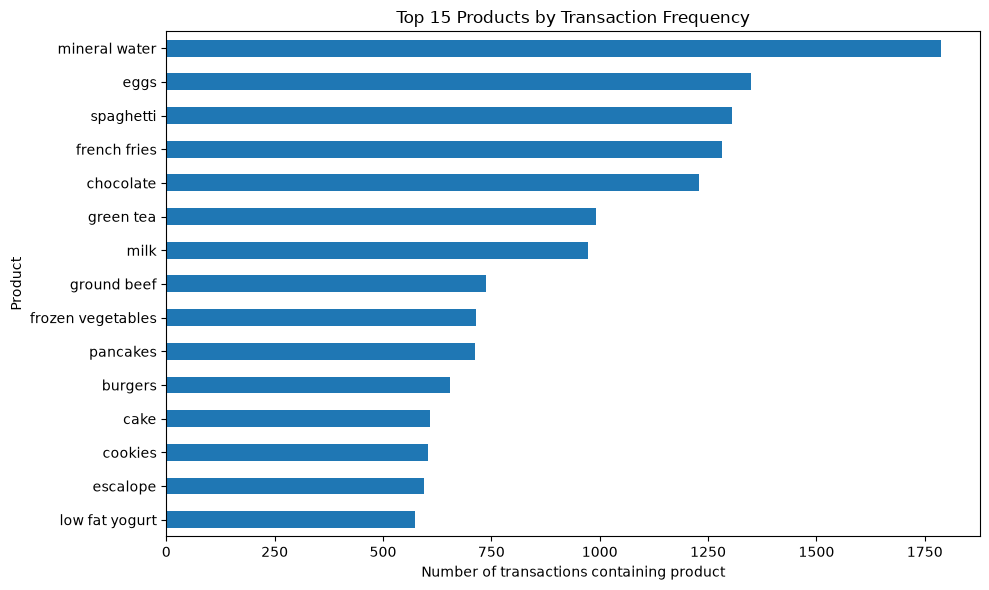

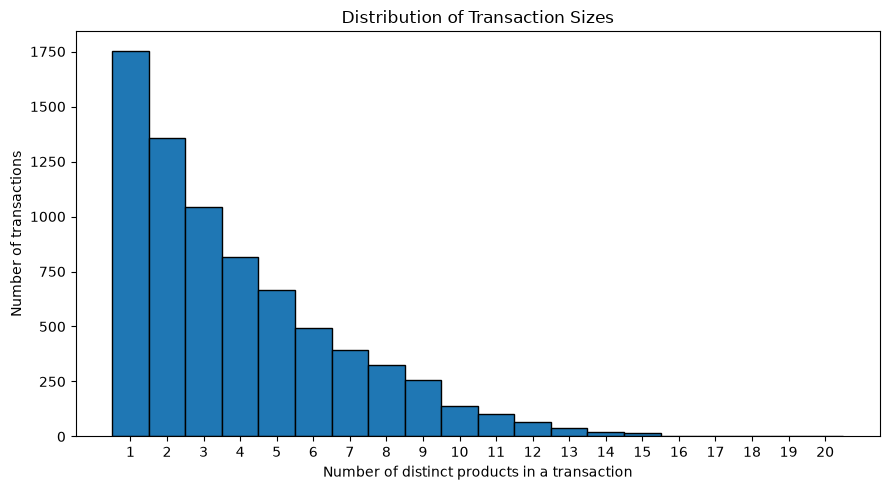

In [4]:
# Graph 1: most frequent products
top_n = 15
top_products = product_counts.head(top_n).sort_values()
plt.figure(figsize=(10, 6))
top_products.plot(kind="barh")
plt.title(f"Top {top_n} Products by Transaction Frequency")
plt.xlabel("Number of transactions containing product")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

# Graph 2: distribution of transaction sizes
plt.figure(figsize=(9, 5))
bins = range(1, int(transaction_sizes.max()) + 2)
plt.hist(transaction_sizes, bins=bins, edgecolor="black", align="left")
plt.title("Distribution of Transaction Sizes")
plt.xlabel("Number of distinct products in a transaction")
plt.ylabel("Number of transactions")
plt.xticks(range(1, int(transaction_sizes.max()) + 1))
plt.tight_layout()
plt.show()

**Interpretation guide:** In the first graph, taller bars indicate products appearing in more baskets and may help prioritize shelf availability or promotions. The histogram shows whether baskets are usually small or large. Use the printed statistics and graph shape to write the dataset-specific observation; do not infer that a frequently purchased item causes another item to be purchased.

## 6. Convert baskets into numerical feature vectors

A binary transaction-item matrix has one row per basket and one column per product. A value of 1 means the product occurs in that basket; 0 means it does not. This representation allows machine-learning algorithms to compare transactions.

In [16]:
item_to_col = {item: i for i, item in enumerate(all_items)}
X = np.zeros((len(transactions), len(all_items)), dtype=np.uint8)
for r, basket in enumerate(transactions):
    for item in basket:
        X[r, item_to_col[item]] = 1

basket_matrix = pd.DataFrame(X, columns=all_items)
print("Transaction-item matrix shape:", basket_matrix.shape)
print("Matrix density (% of entries equal to 1):", round(100 * X.mean(), 3))
display(basket_matrix.iloc[:5, :10])

Transaction-item matrix shape: (7501, 119)
Matrix density (% of entries equal to 1): 3.289


,almonds,antioxydant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea,blueberries,body spray
0,1,1,0,1,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,1,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0


## 7. PCA for dimensionality reduction and visualization

PCA creates new numerical axes that summarize variation in the original item columns. The first two components can be plotted, but they do not necessarily preserve every similarity between baskets. The plot is an exploratory view, not proof that natural clusters exist.

Variance explained by PC1: 6.72 %
Variance explained by PC2: 4.47 %
Combined variance explained: 11.18 %


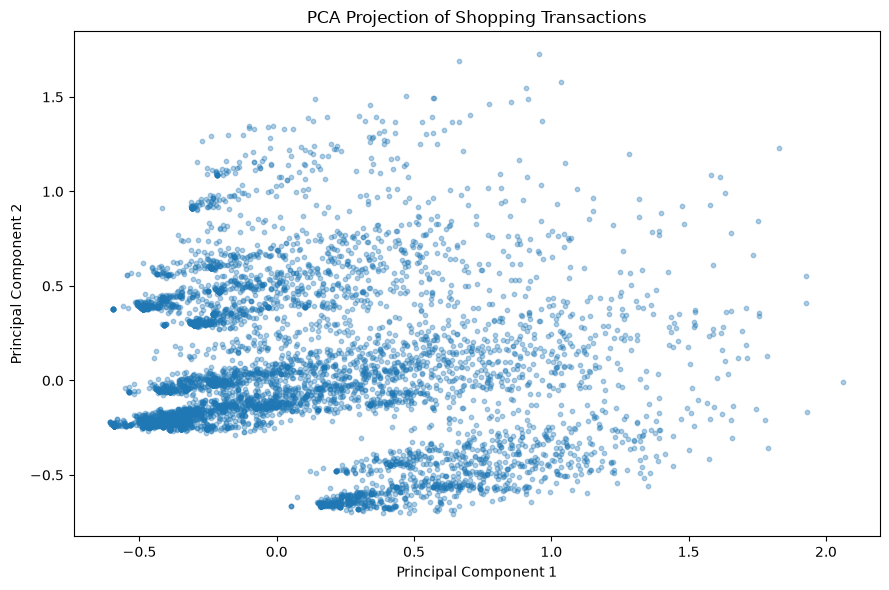

In [17]:
# PCA on binary item vectors; this dataset is small enough for dense PCA.
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X)
explained = pca_2d.explained_variance_ratio_

print("Variance explained by PC1:", round(explained[0] * 100, 2), "%")
print("Variance explained by PC2:", round(explained[1] * 100, 2), "%")
print("Combined variance explained:", round(explained.sum() * 100, 2), "%")

plt.figure(figsize=(9, 6))
plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], s=10, alpha=0.35)
plt.title("PCA Projection of Shopping Transactions")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

**Interpretation:** Points close together have similar projections in the two-dimensional PCA view. Overlap is expected in sparse transaction data. Report the explained-variance percentages printed above to explain how much of the original variation is represented by this two-dimensional chart.

## 8. Prepare a consistent sample for clustering

Hierarchical and spectral clustering can become expensive on thousands of observations. To keep the notebook practical on a student computer, all four algorithms use the **same fixed random sample**. The PCA model is fit to the complete dataset, then 10 PCA components are standardized for clustering. This changes the space in which distances are measured, so results should be interpreted as an exploratory comparison rather than a definitive segmentation.

In [18]:
SAMPLE_SIZE = min(1200, len(X))
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = np.sort(rng.choice(len(X), size=SAMPLE_SIZE, replace=False))

pca_10 = PCA(n_components=min(10, X.shape[1]), random_state=RANDOM_STATE)
X_pca_all = pca_10.fit_transform(X)
X_sample_pca = X_pca_all[sample_idx]
scaler = StandardScaler()
X_cluster = scaler.fit_transform(X_sample_pca)

print("Transactions used for clustering:", len(X_cluster))
print("Clustering feature dimensions:", X_cluster.shape[1])
print("Cumulative variance explained by these PCA components:",
      round(pca_10.explained_variance_ratio_.sum() * 100, 2), "%")

Transactions used for clustering: 1200
Clustering feature dimensions: 10
Cumulative variance explained by these PCA components: 36.21 %


## 9. Fit four clustering algorithms

- **K-means:** divides observations into a chosen number of clusters; here, 4 clusters are used as a comparison setting.
- **Hierarchical clustering:** builds groups by merging similar observations; Ward linkage minimizes within-cluster variance.
- **DBSCAN:** groups dense regions and can label isolated observations as noise (`-1`). Its result depends strongly on `eps` and `min_samples`.
- **Spectral clustering:** uses a graph of local similarities before assigning clusters. It can be useful for non-spherical groups but is more computationally expensive.

The parameter choices are exploratory, not guaranteed to be optimal.

In [19]:
N_CLUSTERS = 4
cluster_labels = {}

cluster_labels["K-means"] = KMeans(
    n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10
).fit_predict(X_cluster)

cluster_labels["Hierarchical"] = AgglomerativeClustering(
    n_clusters=N_CLUSTERS, linkage="ward"
).fit_predict(X_cluster)

# Density-based clustering. Noise points are labelled -1.
cluster_labels["DBSCAN"] = DBSCAN(eps=2.5, min_samples=8).fit_predict(X_cluster)

cluster_labels["Spectral"] = SpectralClustering(
    n_clusters=N_CLUSTERS, affinity="nearest_neighbors",
    n_neighbors=10, assign_labels="kmeans", random_state=RANDOM_STATE
).fit_predict(X_cluster)

for name, labels in cluster_labels.items():
    values, counts = np.unique(labels, return_counts=True)
    print(f"{name}: {dict(zip(values.tolist(), counts.tolist()))}")

K-means: {0: 726, 1: 147, 2: 143, 3: 184}
Hierarchical: {0: 893, 1: 114, 2: 96, 3: 97}
DBSCAN: {-1: 215, 0: 890, 1: 74, 2: 10, 3: 11}
Spectral: {0: 879, 1: 220, 2: 58, 3: 43}


## 10. Evaluate and compare clustering performance

The **silhouette coefficient** ranges from -1 to 1; higher values generally indicate better separation and cohesion. The **Davies–Bouldin index** is non-negative; lower values generally indicate more compact, separated clusters. Both require at least two clusters. For DBSCAN, noise observations are excluded from these metrics; this means its scores are not directly comparable unless the amount of noise is also considered. Metrics are computed in the same standardized PCA feature space used for clustering.

In [20]:
def evaluate_clustering(X_eval, labels, algorithm):
    labels = np.asarray(labels)
    is_dbscan = algorithm == "DBSCAN"
    if is_dbscan:
        keep = labels != -1
        X_eval = X_eval[keep]
        labels = labels[keep]
        noise_fraction = 1 - keep.mean()
    else:
        noise_fraction = 0.0

    n_clusters = len(np.unique(labels))
    n_eval = len(labels)
    if n_clusters < 2 or n_clusters >= n_eval:
        sil = np.nan
        dbi = np.nan
        note = "Metrics undefined: need 2 or more clusters and fewer clusters than observations."
    else:
        sil = silhouette_score(X_eval, labels)
        dbi = davies_bouldin_score(X_eval, labels)
        note = "Noise excluded from scores." if is_dbscan else "All sampled observations scored."

    return {
        "Algorithm": algorithm,
        "Clusters (excluding noise)": n_clusters,
        "Noise fraction": round(noise_fraction, 3),
        "Silhouette coefficient": sil,
        "Davies-Bouldin index": dbi,
        "Evaluation note": note
    }

results = pd.DataFrame([
    evaluate_clustering(X_cluster, labels, name)
    for name, labels in cluster_labels.items()
])
display(results.round(4))
results.to_csv("clustering_metrics.csv", index=False)

,Algorithm,Clusters (excluding noise),Noise fraction,Silhouette coefficient,Davies-Bouldin index,Evaluation note
0,K-means,4,0.000,0.2482,1.8090,All sampled observations scored.
1,Hierarchical,4,0.000,0.2490,1.6766,All sampled observations scored.
2,DBSCAN,4,0.179,0.2164,1.2269,Noise excluded from scores.
3,Spectral,4,0.000,-0.0653,2.4525,All sampled observations scored.


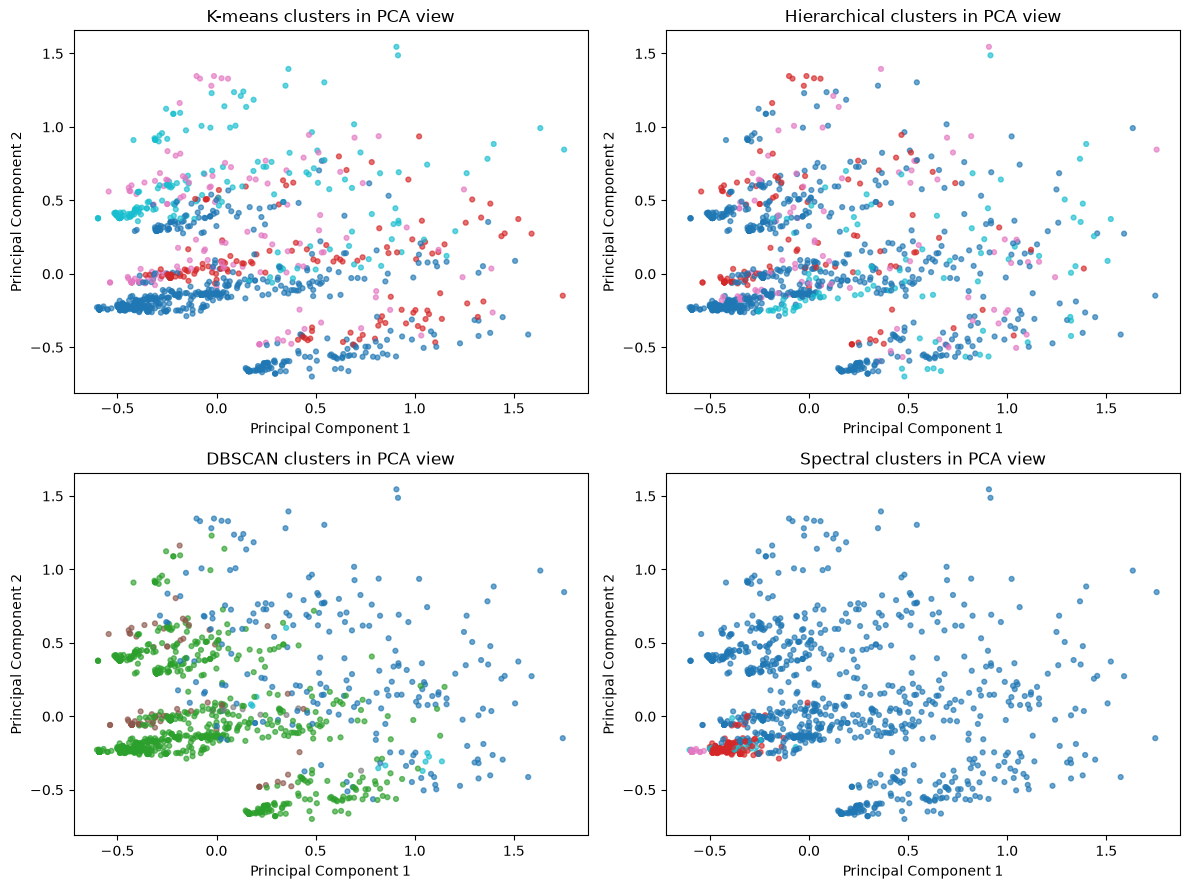

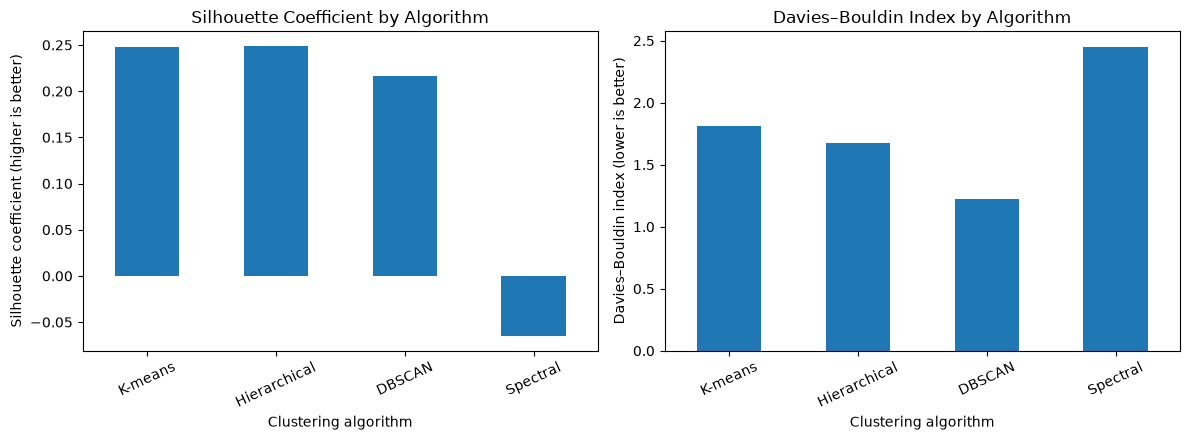

In [10]:
# Graph 3: show cluster assignments in the first two PCA dimensions.
# Labels are from the same sampled transactions used in the comparison.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (name, labels) in zip(axes.ravel(), cluster_labels.items()):
    scatter = ax.scatter(
        X_pca_all[sample_idx, 0], X_pca_all[sample_idx, 1],
        c=labels, s=12, alpha=0.65, cmap="tab10"
    )
    ax.set_title(f"{name} clusters in PCA view")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

# Metric comparison plots (NaN values are naturally omitted).
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
results.set_index("Algorithm")["Silhouette coefficient"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Silhouette Coefficient by Algorithm")
axes[0].set_xlabel("Clustering algorithm")
axes[0].set_ylabel("Silhouette coefficient (higher is better)")
axes[0].tick_params(axis="x", rotation=25)

results.set_index("Algorithm")["Davies-Bouldin index"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Davies–Bouldin Index by Algorithm")
axes[1].set_xlabel("Clustering algorithm")
axes[1].set_ylabel("Davies–Bouldin index (lower is better)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## 11. Interpreting the results

Use the actual `results` table and cluster-size output above. Do not declare one algorithm the winner based on one metric alone. Consider:
- whether a metric is defined;
- whether DBSCAN labels many transactions as noise;
- the silhouette score (higher is better);
- the Davies–Bouldin index (lower is better);
- cluster sizes and whether the groups are interpretable for the business.

A useful business follow-up is to inspect the most common products within each cluster. Clusters describe similarity in baskets, not customer identity, because this dataset does not provide customer IDs, dates, prices or quantities.

In [21]:
# Summarize most common products within each non-noise cluster.
sample_baskets = [transactions[i] for i in sample_idx]
cluster_product_rows = []
for name, labels in cluster_labels.items():
    for label in sorted(set(labels)):
        if label == -1:
            continue
        basket_ids = np.where(labels == label)[0]
        counts = {}
        for idx in basket_ids:
            for item in sample_baskets[idx]:
                counts[item] = counts.get(item, 0) + 1
        top = sorted(counts.items(), key=lambda pair: pair[1], reverse=True)[:5]
        cluster_product_rows.append({
            "Algorithm": name,
            "Cluster": int(label),
            "Transactions": len(basket_ids),
            "Top products": ", ".join([f"{item} ({count})" for item, count in top])
        })

cluster_summary = pd.DataFrame(cluster_product_rows)
display(cluster_summary)
cluster_summary.to_csv("cluster_product_summary.csv", index=False)

,Algorithm,Cluster,Transactions,Top products
0,K-means,0,726,"mineral water (154), eggs (125), spaghetti (12..."
1,K-means,1,147,"chocolate (147), mineral water (53), spaghetti..."
2,K-means,2,143,"green tea (143), french fries (38), spaghetti ..."
3,K-means,3,184,"french fries (184), chocolate (45), eggs (43),..."
4,Hierarchical,0,893,"mineral water (198), eggs (160), french fries ..."
5,Hierarchical,1,114,"green tea (114), french fries (29), spaghetti ..."
6,Hierarchical,2,96,"pancakes (96), mineral water (25), eggs (24), ..."
7,Hierarchical,3,97,"ground beef (97), spaghetti (40), mineral wate..."
8,DBSCAN,0,890,"mineral water (166), eggs (143), french fries ..."
9,DBSCAN,1,74,"green tea (74), french fries (15), mineral wat..."


## 12. Limitations

1. **No customer or time identifiers:** this analysis groups baskets, not customers or shopping journeys.
2. **Binary encoding:** it records whether a product is present, not quantity, price, revenue or profit.
3. **Sparse data:** most products occur in only a small fraction of baskets, which can make distances less informative.
4. **PCA information loss:** reducing dimensions can discard some product-level differences.
5. **Sampling:** clustering metrics describe the fixed sample, not a full-data clustering result.
6. **Parameter sensitivity:** K-means, DBSCAN and spectral clustering depend on parameter choices; further tuning and stability checks are needed.
7. **Metrics are imperfect:** numerical scores do not guarantee useful business segments, and DBSCAN's noise-excluded scores must be interpreted with its noise fraction.


